# Explainable Hybrid Feature Selection for IDS in IoMT (CIC-IoMT-2024, WiFi + MQTT)
Implementation of Berrezzek et al. (arXiv 2608.00869): Pearson filter -> Feature Importance (A) + SHAP (B) -> HFS = (A ∩ B) + 95%·(A − B) -> RF / LightGBM -> SHAP + LIME.

**Kaggle setup (once):** right side panel -> *Add Data* -> add the CIC-IoMT-2024 train CSV dataset (and test CSV if separate) -> *Settings -> Internet ON* (needed only for `pip install lime`).
Run cells top to bottom (Run All).

In [1]:
!pip -q install lime

In [2]:
import os, glob, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from lime.lime_tabular import LimeTabularExplainer
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, ConfusionMatrixDisplay)
warnings.filterwarnings('ignore')

# ---------------- CONFIG (change here only) ----------------
SEED          = 42
INPUT_DIR     = '/kaggle/input'
OUT_DIR       = '/kaggle/working'
MAX_PER_CLASS = 200_000   # rows per class after balancing; None = use ALL benign rows (slower)
TEST_SIZE     = 0.30      # paper: 70/30 split
PEARSON_THR   = 0.90      # paper: |r| > 0.9
THR_MULT      = 1.0       # selection threshold = THR_MULT * mean importance (tune to get 5 / 13 features)
HFS_FRAC      = 0.95      # paper: 95 %
SHAP_N        = 2000      # rows used to compute SHAP values
CLASSIFIERS   = ['RF', 'LGBM']
os.makedirs(OUT_DIR, exist_ok=True)

## 1. Find the CSV files on Kaggle

In [3]:
all_csvs = sorted(glob.glob(f'{INPUT_DIR}/**/*.csv', recursive=True))
print(len(all_csvs), 'csv files found')
for f in all_csvs[:80]:
    print(f'{os.path.getsize(f)/1e6:10.1f} MB  {f}')

def is_iomt_csv(f):
    try:
        cols = pd.read_csv(f, nrows=0).columns
    except Exception:
        return False
    return {'Header_Length', 'IAT', 'Rate', 'syn_flag_number'}.issubset(set(cols))

FILES = [f for f in all_csvs if is_iomt_csv(f)]
# If you want only some files, set FILES manually, e.g. FILES = ['/kaggle/input/xyz/train.csv', '/kaggle/input/xyz/test.csv']
print('\nUsing', len(FILES), 'IoMT files:')
for f in FILES: print('  ', f)

2 csv files found
     377.7 MB  /kaggle/input/datasets/limamateus/cic-iomt-2024-wifi-mqtt/CIC_IoMT_2024_WiFi_MQTT_test.csv
    1694.6 MB  /kaggle/input/datasets/limamateus/cic-iomt-2024-wifi-mqtt/CIC_IoMT_2024_WiFi_MQTT_train.csv

Using 2 IoMT files:
   /kaggle/input/datasets/limamateus/cic-iomt-2024-wifi-mqtt/CIC_IoMT_2024_WiFi_MQTT_test.csv
   /kaggle/input/datasets/limamateus/cic-iomt-2024-wifi-mqtt/CIC_IoMT_2024_WiFi_MQTT_train.csv


## 2. Load + merge (train + test files merged and shuffled, as in the paper)

In [4]:
dfs = []
for f in FILES:
    cols = pd.read_csv(f, nrows=0).columns
    dtypes = {c: np.float32 for c in cols if c != 'label'}
    d = pd.read_csv(f, dtype=dtypes)
    if 'label' not in d.columns:                      # per-attack files: label comes from file name
        d['label'] = os.path.splitext(os.path.basename(f))[0]
    dfs.append(d)
    print(os.path.basename(f), d.shape)
df = pd.concat(dfs, ignore_index=True); del dfs

# binary task: benign (0) vs attack (1)
df['is_attack'] = (~df['label'].astype(str).str.lower().str.contains('benign')).astype(np.int8)
print('\nTotal:', df.shape)
print(df['is_attack'].value_counts().rename({0: 'benign', 1: 'attack'}))
print(df['label'].value_counts())

CIC_IoMT_2024_WiFi_MQTT_test.csv (1614182, 46)
CIC_IoMT_2024_WiFi_MQTT_train.csv (7160831, 46)

Total: (8775013, 47)
is_attack
attack    8544674
benign     230339
Name: count, dtype: int64
label
TCP_IP-DDoS-UDP2_train      207295
TCP_IP-DDoS-UDP3_train      206604
TCP_IP-DDoS-UDP4_train      206343
TCP_IP-DDoS-UDP1_train      206170
TCP_IP-DDoS-UDP1_test       205654
                             ...  
MQTT-Malformed_Data_test      1747
ARP_Spoofing_test             1744
Recon-VulScan_test            1034
Recon-Ping_Sweep_train         740
Recon-Ping_Sweep_test          186
Name: count, Length: 72, dtype: int64


## 3. Balance classes, 70/30 split, pre-processing (fit on TRAIN only -> no leakage)
The paper reports accuracy ≈ F1 with recall > precision, which is what you get on a ~50/50 test set, so benign and attack are balanced here (all benign rows + equal number of random attack rows).
Pre-processing as in the paper: inf -> NaN, median imputation, Z-score.

In [5]:
benign = df[df.is_attack == 0]
attack = df[df.is_attack == 1]
n = len(benign) if MAX_PER_CLASS is None else min(len(benign), MAX_PER_CLASS)
n = min(n, len(attack))
data = (pd.concat([benign.sample(n, random_state=SEED), attack.sample(n, random_state=SEED)])
          .sample(frac=1, random_state=SEED).reset_index(drop=True))
del df, benign, attack

y = data['is_attack'].values
X = data.drop(columns=['label', 'is_attack']).replace([np.inf, -np.inf], np.nan)
FEATURES = list(X.columns)
print('Balanced data:', X.shape, '| features:', len(FEATURES))

Xtr_raw, Xte_raw, ytr, yte = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)
imputer = SimpleImputer(strategy='median').fit(Xtr_raw)
scaler  = StandardScaler().fit(imputer.transform(Xtr_raw))

def prep(Xr):
    return pd.DataFrame(scaler.transform(imputer.transform(Xr)), columns=FEATURES).astype(np.float32)

Xtr, Xte = prep(Xtr_raw), prep(Xte_raw)
del data, X, Xtr_raw, Xte_raw
print('train:', Xtr.shape, ' test:', Xte.shape, ' attack share in test: %.3f' % yte.mean())

Balanced data: (400000, 45) | features: 45
train: (280000, 45)  test: (120000, 45)  attack share in test: 0.500


## 4. Pearson correlation filter (|r| > 0.9, computed on train only)

In [6]:
def pearson_filter(Xtrain, thr=0.9):
    corr  = Xtrain.corr().abs()
    upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    drop  = [c for c in upper.columns if (upper[c] > thr).any()]
    return [c for c in Xtrain.columns if c not in drop], drop

ALL_COLS = list(Xtr.columns)
PEARSON_COLS, DROPPED = pearson_filter(Xtr, PEARSON_THR)
print(f'Before Pearson: {len(ALL_COLS)} features | After: {len(PEARSON_COLS)} | Dropped {len(DROPPED)}:')
print(DROPPED)

Before Pearson: 45 features | After: 34 | Dropped 11:
['Srate', 'UDP', 'IPv', 'LLC', 'AVG', 'Tot size', 'Number', 'Magnitue', 'Radius', 'Covariance', 'Weight']


## 5. Hybrid Feature Selection: A = Feature Importance, B = SHAP, HFS = (A ∩ B) + 95%·(A − B)

In [7]:
def make_model(kind):
    if kind == 'RF':
        return RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1)
    return LGBMClassifier(random_state=SEED, n_jobs=-1, verbose=-1)   # standard configuration

def evaluate(m, Xt, yt):
    p, pr = m.predict(Xt), m.predict_proba(Xt)[:, 1]
    return dict(Accuracy=accuracy_score(yt, p), Precision=precision_score(yt, p),
                Recall=recall_score(yt, p), F1=f1_score(yt, p), AUC=roc_auc_score(yt, pr))

def class1(sv):
    """SHAP output -> (n_samples, n_features) for the 'attack' class (works for old and new shap versions)."""
    if isinstance(sv, list): sv = sv[1]
    sv = np.asarray(sv)
    if sv.ndim == 3: sv = sv[:, :, 1]
    return sv

def select_by_score(score, mult=THR_MULT):
    s = score.sort_values(ascending=False)
    keep = s[s >= s.mean() * mult].index.tolist()
    return keep if keep else [s.index[0]]

def fi_select(model, cols):                      # set A (ranked by importance)
    fi = pd.Series(model.feature_importances_, index=cols)
    return select_by_score(fi), fi

def shap_select(model, Xdf):                     # set B (ranked by mean |SHAP|)
    sample = Xdf.sample(min(SHAP_N, len(Xdf)), random_state=SEED)
    sv = class1(shap.TreeExplainer(model).shap_values(sample))
    sh = pd.Series(np.abs(sv).mean(axis=0), index=Xdf.columns)
    return select_by_score(sh), sh

def hybrid(A, B, frac=HFS_FRAC):
    inter = [f for f in A if f in B]             # A ∩ B  (agreement)
    diff  = [f for f in A if f not in B]         # A − B  (already ranked by FI)
    k     = int(np.floor(frac * len(diff)))      # top 95 % of A − B
    H = inter + diff[:k]
    return H if H else A

## 6. Run all experiments (RF / LightGBM × with / without Pearson × Baseline, +SHAP, +FI, Hybrid)

In [8]:
store, rows = {}, []
t0 = time.time()
for clf in CLASSIFIERS:
    for use_p in [False, True]:
        cols = PEARSON_COLS if use_p else ALL_COLS
        base = make_model(clf).fit(Xtr[cols], ytr)
        A, fi = fi_select(base, cols)
        B, sh = shap_select(base, Xtr[cols])
        H = hybrid(A, B)
        sets = {'Baseline': cols, '+ SHAP': B, '+ FI': A, 'Hybrid': H}
        models = {'Baseline': base}
        for name in ['+ SHAP', '+ FI', 'Hybrid']:
            models[name] = make_model(clf).fit(Xtr[sets[name]], ytr)
        for name, m in models.items():
            rows.append(dict(Model=clf, Pearson='With' if use_p else 'Without', Variant=name,
                             n_features=len(sets[name]), **evaluate(m, Xte[sets[name]], yte)))
        store[(clf, use_p)] = dict(sets=sets, models=models, fi=fi, shap=sh)
        print(f'{clf:5s} Pearson={use_p!s:5s} |A|={len(A):2d} |B|={len(B):2d} |A∩B|={len([f for f in A if f in B]):2d} '
              f'|HFS|={len(H):2d}   [{time.time()-t0:.0f}s]')
results = pd.DataFrame(rows)

RF    Pearson=False |A|= 9 |B|=14 |A∩B|= 9 |HFS|= 9   [236s]
RF    Pearson=True  |A|=10 |B|=10 |A∩B|=10 |HFS|=10   [461s]
LGBM  Pearson=False |A|=16 |B|= 7 |A∩B|= 7 |HFS|=15   [473s]
LGBM  Pearson=True  |A|=12 |B|= 4 |A∩B|= 4 |HFS|=11   [483s]


## 7. Results table (compare with the paper's Table I and II)

In [9]:
PAPER_ACC = {
 ('RF','Without'):   {'Baseline':.978,'+ SHAP':.975,'+ FI':.971,'Hybrid':.972},
 ('RF','With'):      {'Baseline':.980,'+ SHAP':.976,'+ FI':.970,'Hybrid':.978},
 ('LGBM','Without'): {'Baseline':.995,'+ SHAP':.960,'+ FI':.994,'Hybrid':.960},
 ('LGBM','With'):    {'Baseline':.996,'+ SHAP':.962,'+ FI':.995,'Hybrid':.985},
}
results['Paper_Accuracy'] = [PAPER_ACC[(r.Model, r.Pearson)][r.Variant] for r in results.itertuples()]
results['Variant'] = results.apply(lambda r: r.Variant.replace('Baseline', r.Model) if r.Variant == 'Baseline' else f"{r.Model} {r.Variant}", axis=1)
show = results.round(4)
display(show)
show.to_csv(f'{OUT_DIR}/results_iomt.csv', index=False)

print('\nTable V analogue - features kept by Hybrid (with Pearson):')
for clf in CLASSIFIERS:
    print(f"  Hybrid {clf}: {len(store[(clf, True)]['sets']['Hybrid'])} features ->", store[(clf, True)]['sets']['Hybrid'])

,Model,Pearson,Variant,n_features,Accuracy,Precision,Recall,F1,AUC,Paper_Accuracy
0,RF,Without,RF,45,0.9992,1.0000,0.9984,0.9992,0.9999,0.978
1,RF,Without,RF + SHAP,14,0.9991,0.9999,0.9982,0.9991,0.9999,0.975
2,RF,Without,RF + FI,9,0.9972,0.9994,0.9950,0.9972,0.9993,0.971
3,RF,Without,RF Hybrid,9,0.9972,0.9994,0.9950,0.9972,0.9993,0.972
4,RF,With,RF,34,0.9991,1.0000,0.9983,0.9991,0.9999,0.980
5,RF,With,RF + SHAP,10,0.9989,0.9998,0.9980,0.9989,0.9997,0.976
6,RF,With,RF + FI,10,0.9989,0.9998,0.9980,0.9989,0.9997,0.970
7,RF,With,RF Hybrid,10,0.9989,0.9998,0.9980,0.9989,0.9997,0.978
8,LGBM,Without,LGBM,45,0.9993,0.9999,0.9988,0.9993,1.0000,0.995
9,LGBM,Without,LGBM + SHAP,7,0.9988,0.9998,0.9977,0.9988,0.9999,0.960



Table V analogue - features kept by Hybrid (with Pearson):
  Hybrid RF: 10 features -> ['rst_count', 'Max', 'ack_flag_number', 'Header_Length', 'Variance', 'Min', 'psh_flag_number', 'Std', 'Tot sum', 'IAT']
  Hybrid LGBM: 11 features -> ['IAT', 'Rate', 'rst_count', 'Max', 'Header_Length', 'syn_count', 'Duration', 'Tot sum', 'Std', 'HTTPS', 'Min']


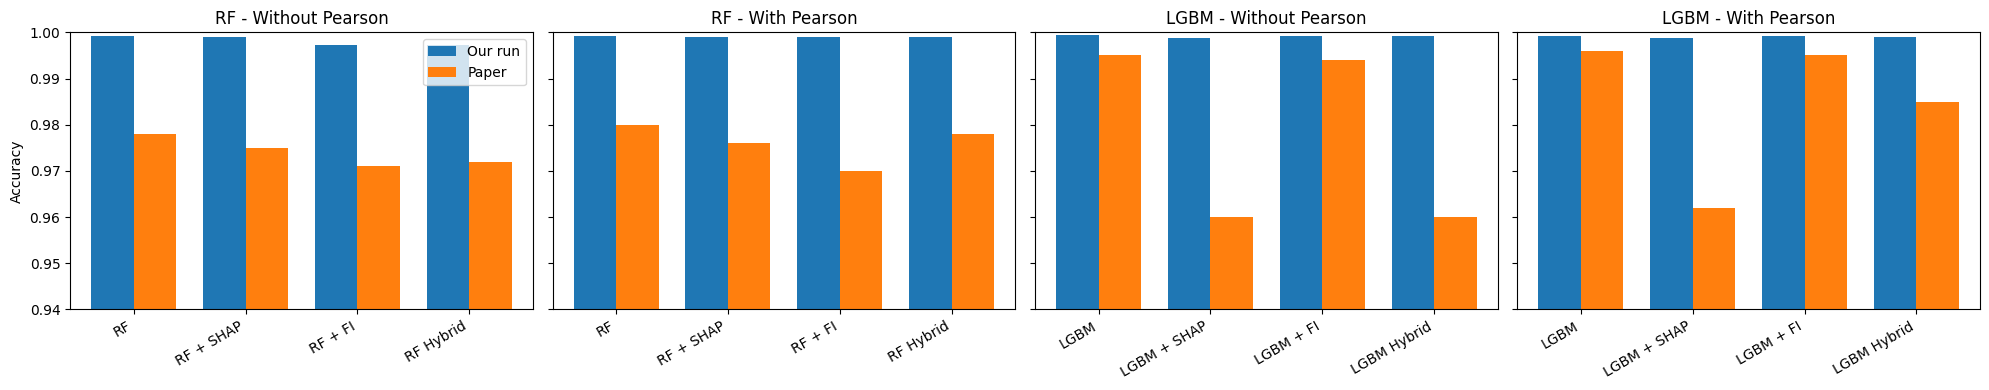

In [10]:
fig, axes = plt.subplots(1, len(CLASSIFIERS) * 2, figsize=(5 * len(CLASSIFIERS) * 2, 4), sharey=True)
k = 0
for clf in CLASSIFIERS:
    for pear in ['Without', 'With']:
        d = results[(results.Model == clf) & (results.Pearson == pear)]
        x = np.arange(len(d)); w = 0.38
        axes[k].bar(x - w/2, d.Accuracy, w, label='Our run')
        axes[k].bar(x + w/2, d.Paper_Accuracy, w, label='Paper')
        axes[k].set_xticks(x); axes[k].set_xticklabels(d.Variant, rotation=30, ha='right')
        axes[k].set_title(f'{clf} - {pear} Pearson'); axes[k].set_ylim(0.94, 1.0)
        k += 1
axes[0].set_ylabel('Accuracy'); axes[0].legend()
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/accuracy_vs_paper.png', dpi=150); plt.show()

## 8. Confusion matrices (Hybrid models, with Pearson)

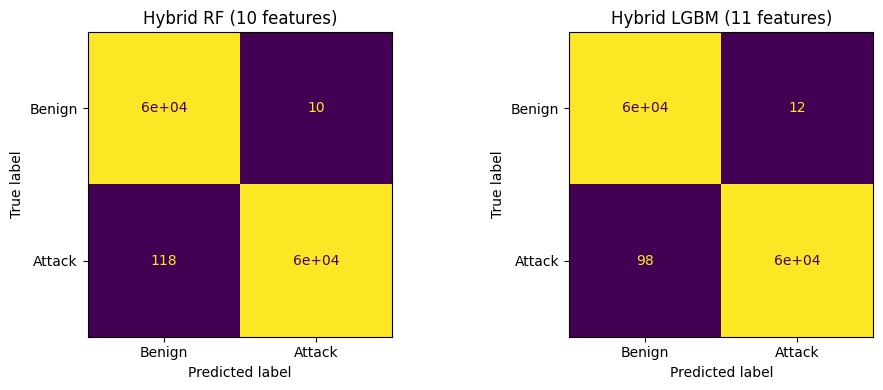

In [11]:
fig, axes = plt.subplots(1, len(CLASSIFIERS), figsize=(5 * len(CLASSIFIERS), 4))
axes = np.atleast_1d(axes)
for ax, clf in zip(axes, CLASSIFIERS):
    s = store[(clf, True)]; feats = s['sets']['Hybrid']
    ConfusionMatrixDisplay.from_estimator(s['models']['Hybrid'], Xte[feats], yte,
                                          display_labels=['Benign', 'Attack'], ax=ax, colorbar=False)
    ax.set_title(f'Hybrid {clf} ({len(feats)} features)')
plt.tight_layout(); plt.savefig(f'{OUT_DIR}/confusion_matrices.png', dpi=150); plt.show()

## 9. SHAP global explanations (Fig. 6 / Fig. 7 of the paper)

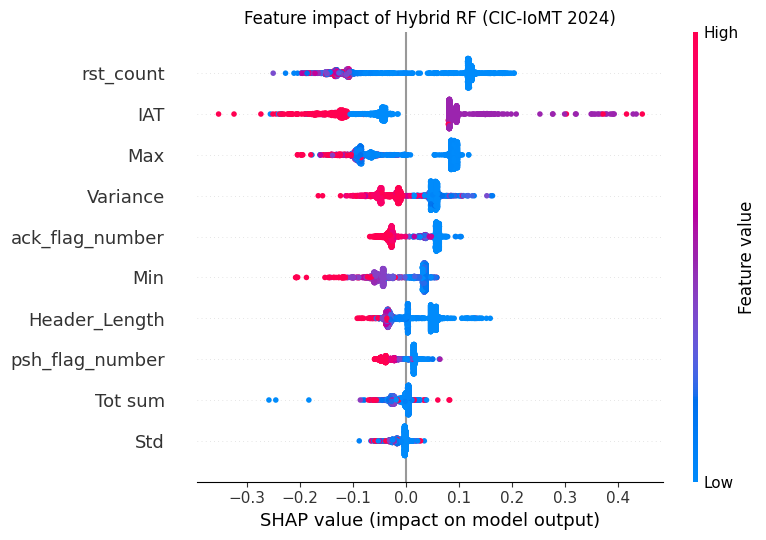

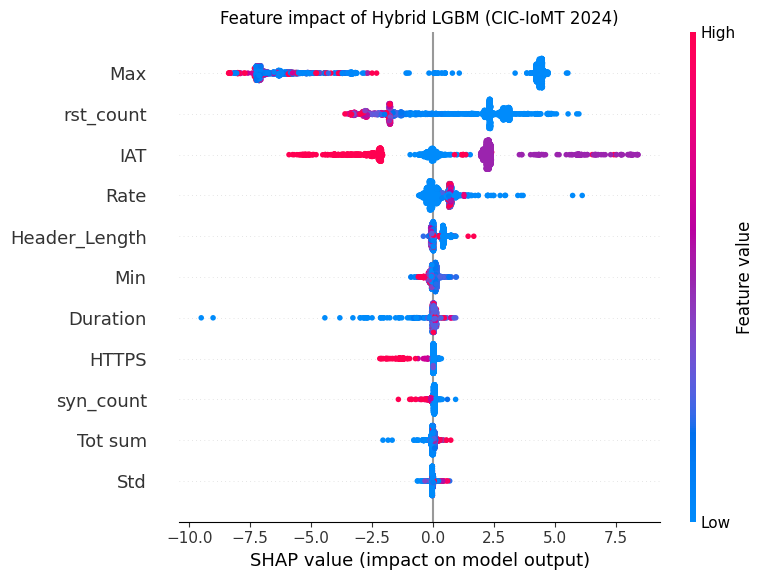

In [12]:
for clf in CLASSIFIERS:
    s = store[(clf, True)]; feats = s['sets']['Hybrid']
    sample = Xte[feats].sample(min(SHAP_N, len(Xte)), random_state=SEED)
    sv = class1(shap.TreeExplainer(s['models']['Hybrid']).shap_values(sample))
    plt.figure()
    shap.summary_plot(sv, sample, show=False)
    plt.title(f'Feature impact of Hybrid {clf} (CIC-IoMT 2024)')
    plt.tight_layout(); plt.savefig(f'{OUT_DIR}/shap_{clf}.png', dpi=150, bbox_inches='tight'); plt.show()

## 10. LIME local explanations (Tables VI / VII of the paper)

In [13]:
for clf in CLASSIFIERS:
    s = store[(clf, True)]; feats = s['sets']['Hybrid']; m = s['models']['Hybrid']
    pred = m.predict(Xte[feats])
    idx = int(np.where((pred == 1) & (yte == 1))[0][0])          # first correctly detected attack
    explainer = LimeTabularExplainer(Xtr[feats].values, feature_names=feats,
                                     class_names=['Benign', 'Attack'], mode='classification',
                                     discretize_continuous=True, random_state=SEED)
    exp = explainer.explain_instance(Xte[feats].values[idx],
                                     lambda a: m.predict_proba(pd.DataFrame(a, columns=feats)),
                                     num_features=min(5, len(feats)))
    print(f'\nLIME explanation - Hybrid {clf} (test sample #{idx}, predicted = Attack)')
    display(pd.DataFrame(exp.as_list(), columns=['Feature condition', 'LIME weight']).round(6))


LIME explanation - Hybrid RF (test sample #0, predicted = Attack)


,Feature condition,LIME weight
0,-0.00 < IAT <= 1.40,0.223450
1,Max <= -0.46,0.054233
2,Variance <= -1.01,0.049279
3,ack_flag_number <= -1.04,0.048017
4,psh_flag_number <= -0.86,0.044824



LIME explanation - Hybrid LGBM (test sample #0, predicted = Attack)


,Feature condition,LIME weight
0,Max <= -0.46,0.333271
1,-0.28 < Rate <= -0.27,0.148133
2,-0.00 < IAT <= 1.40,0.122267
3,HTTPS <= -0.26,0.110847
4,rst_count <= -0.63,-0.061131


## 11. Notes for the presentation
* Exact numbers will not match the paper to the 3rd decimal: the paper does not give the random seed, the exact files used or how the data was balanced. Results within ~1-2 points of the paper's tables are expected.
* Pearson filter removes highly correlated features; HFS then keeps features that both Feature Importance and SHAP agree on, plus the top 95 % of the features only FI selected.
* To get closer to the paper's feature counts (5 for Hybrid RF, 13 for Hybrid LGBM), change `THR_MULT` (e.g. 1.25 -> fewer features, 0.75 -> more) and re-run from Section 6.